# DSCI-503: Project 04

**Mame Diarra N'daw**

[PLACEHOLDER_FOR_NOTEBOOK_LINK]

## Getting Started

Follow the instructions below to copy this notebook and to perform some initial setup.

1. Copy this notebook by selecting `File > Save a copy in Drive`.
2. A new window should open for the copied notebook. Move the new notebook to your course folder in Google Drive by selecting `File > Move` and then selecting the desired folder.
3. Update the name of the notebook by removing "Copy of" and replacing "Username" with your actual username.
4. Update the first cell in the notebook by replacing "Student Name" with your actual name.
5. Do not edit the line that says `PLACEHOLDER_FOR_NOTEBOOK_LINK`. This will be used by the notebook renderer tool to insert a link to your Colab notebook.
6. Enable link sharing for your notebook.

## Background

In this project, we will be working with the Forest Cover dataset. Additional information about this dataset can be found here: [Kaggle: Forest Cover Type Prediction](https://www.kaggle.com/c/forest-cover-type-prediction).

Your goal will be to create a model to generate predictions about the type of forest cover in a particular wilderness region based on cartographic information. The data was collected from the Roosevelt National Forest in Northern Colorado. Each observation represents a 30 meter by 30 meter patch of land.

**Note:** Any time that you are asked to display a DataFrame in this assignment, you should do so without using the `print()` function.


## Import Statements

Import `numpy`, `pandas`, and `matplotlib.pyplot` using the standard aliases. Import the following classes and functions from the relevant modules in scikit-learn: `train_test_split`, `OneHotEncoder`, `LogisticRegression`, `DecisionTreeClassifier`, `RandomForestClassifier`, `classification_report`, and `confusion_matrix`. **No other packages should be used in this project.**

Run the cell below to import these packages.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

## Downloading the Data Files

This project uses the data file `forest_cover.txt`. Run the cell below to download the course data files so that they are available to your notebook.


In [ ]:
%%capture
!rm data -r
!git clone https://github.com/drbeane/python_courses.git data
!mv data/forest_cover.txt .

## Part 1: Loading the Dataset; Preliminary Analysis

In this section, we will load the data into a DataFrame and explore the structure of the dataset.

### Problem Background

The dataset contains the following columns:

* **Elevation** – The average elevation of the region, in meters.
* **Aspect** – A measure of the direction the slope of the region faces, in degrees, with 0 degrees indicating North.
* **Slope** – The average slope of the region, in degrees.
* **Horizontal_Distance_To_Hydrology** – The horizontal distance to the nearest surface water.
* **Vertical_Distance_To_Hydrology** – The vertical distance to the nearest surface water.
* **Horizontal_Distance_To_Roadways** – The horizontal distance to the nearest roadway.
* **Hillshade_9am** – A measure of the amount of shade the region has at 9 am during the summer solstice.
* **Hillshade_Noon** – A measure of the amount of shade the region has at noon during the summer solstice.
* **Hillshade_3pm** – A measure of the amount of shade the region has at 3 pm during the summer solstice.
* **Horizontal_Distance_To_Fire_Points** – The horizontal distance to the nearest wildfire ignition points.
* **Wilderness_Area** – A categorical variable indicating which of four wilderness areas the region resides in. The names of the four areas are: Rawah, Neota, Comanche Peak, and Cache la Poudre.
* **Soil_Type** – A categorical variable indicating which of 40 soil types is predominant in the region. The soil types are encoded as integers with values 1–40.
* **Cover_Type** – A categorical variable indicating which of 7 forest cover types is predominant in the region. The cover types are encoded as integers with values 1–7:
 1. Spruce/Fir
 2. Lodgepole Pine
 3. Ponderosa Pine
 4. Cottonwood/Willow
 5. Aspen
 6. Douglas-Fir
 7. Krummholz

### Instructions

The data is stored in the tab-delimited text file `forest_cover.txt`. Load the data into a DataFrame named `fc`. Use the `head()` method to display the first 5 rows of this DataFrame.


In [ ]:
fc = pd.read_csv('forest_cover.txt', sep='\t')

fc.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area,Soil_Type,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,Rawah,29,5
1,2590,56,2,212,-6,390,220,235,151,6225,Rawah,29,5
2,2804,139,9,268,65,3180,234,238,135,6121,Rawah,12,2
3,2785,155,18,242,118,3090,238,238,122,6211,Rawah,30,2
4,2595,45,2,153,-1,391,220,234,150,6172,Rawah,29,5


We will now determine the size of the dataset. Print the shape of the `fc` DataFrame, and note what the results tell you about the number of observations.


In [ ]:
fc.shape

(15120, 13)

We will now inspect the distribution of cover types in the dataset.

Without creating any new DataFrame variables, select the `Cover_Type` column from `fc`, then call its `value_counts()` method, followed by the `sort_index()` method. Display the result.

You should see that the seven cover types are equally represented in the dataset. This is an important observation. If we were to create a model that just guesses the cover type at random, we would expect that it would be correct 1/7 of the time, and thus have an accuracy of 0.1429. This will provide us with an important benchmark for evaluating our models.


In [ ]:
fc['Cover_Type'].value_counts().sort_index()

,count
Cover_Type,
1,2160
2,2160
3,2160
4,2160
5,2160
6,2160
7,2160


We will now create a list of seven colors to be used as a palette in plots that you will create later.

Create a list named `palette` containing seven named colors. The colors should be easily distinguishable from each other. You are welcome to select your own colors, or to use the following list:

```python
['orchid', 'lightcoral', 'orange', 'gold', 'lightgreen', 'deepskyblue', 'cornflowerblue']
```


In [ ]:
palette = ['orchid', 'lightcoral', 'orange', 'gold', 'lightgreen', 'deepskyblue', 'cornflowerblue']

## Part 2: Distribution of Cover Type by Wilderness Area

In this section, we will explore the relationship between cover type and wilderness area. We will start by determining the distribution of the wilderness areas within our dataset.

Without creating any new DataFrame variables, select the `Wilderness_Area` column from `fc`, then call its `value_counts()` method, followed by the `sort_index()` method. Display the result.


In [ ]:
fc['Wilderness_Area'].value_counts().sort_index()

,count
Wilderness_Area,
Cache la Poudre,4675
Comanche Peak,6349
Neota,499
Rawah,3597


We will now create a DataFrame to determine how many regions of each cover type are in each of the four wilderness areas.

Use `pd.crosstab()` to count the number of regions of each cover type that are in each of the four wilderness areas. Pass this function the `Cover_Type` column as its first argument and the `Wilderness_Area` column as the second argument. Store the results in a DataFrame named `ct_by_wa` and then display this DataFrame.


In [ ]:
ct_by_wa = pd.crosstab(fc['Cover_Type'], fc['Wilderness_Area'])

ct_by_wa

Wilderness_Area,Cache la Poudre,Comanche Peak,Neota,Rawah
Cover_Type,,,,
1,0,917,181,1062
2,20,940,66,1134
3,1297,863,0,0
4,2160,0,0,0
5,0,1304,0,856
6,1198,962,0,0
7,0,1363,252,545


We will visually represent the information in the DataFrame you just created in the form of a stacked bar chart.

Perform the following steps in a single cell:

1. Start by converting the count information into proportions. Create a DataFrame named `ct_by_wa_props` by dividing `ct_by_wa` by the column sums of `ct_by_wa`. The column sums can be calculated using `np.sum()` or the DataFrame `sum()` method.
2. We will be creating a stacked bar chart, so we need to know where the bottom of each bar should be located. This can be calculated as follows: `bb = np.cumsum(ct_by_wa_props) - ct_by_wa_props`.
3. Create a Matplotlib figure, setting the figure size to `[8, 4]`.
4. Loop over the rows of `ct_by_wa_props`. Each time this loop executes, add a bar chart to the figure according to the following specifications:
 * The height of the bars should be determined by the current row of `ct_by_wa_props`.
 * The bottom position of each bar should be determined by the current row of `bb`.
 * Each bar should have a black border, and a fill color determined by the current value of `palette`.
 * The label for the legend should be set to the value of `Cover_Type` associated with the current row.
5. Set the labels for the x and y axes to be `"Wilderness Area"` and `"Proportion"`. Set the title to be `"Distribution of Cover Type by Wilderness Area"`.
6. Add a legend to the plot. Set the `bbox_to_anchor` parameter to place the legend to the right of the plot, near the top.
7. Display the figure using `plt.show()`.

**Note:** You performed a task very similar to this in Problem 8 of Homework 05.


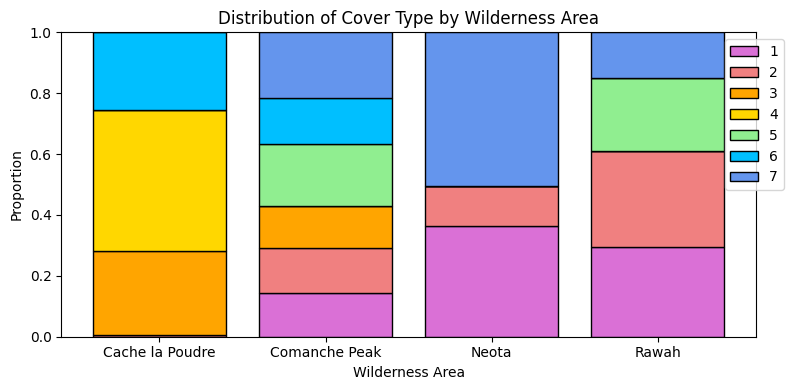

In [ ]:
ct_by_wa_props = ct_by_wa / ct_by_wa.sum()
bb = np.cumsum(ct_by_wa_props) - ct_by_wa_props

plt.figure(figsize=[8, 4])

for i in range(len(ct_by_wa_props)):
  plt.bar(
      ct_by_wa_props.columns,
      ct_by_wa_props.iloc[i],
      bottom = bb.iloc[i],
      color = palette[i],
      edgecolor= 'k',
      label=str(ct_by_wa_props.index[i])
  )

  plt.xlabel("Wilderness Area")
  plt.ylabel("Proportion")
  plt.title("Distribution of Cover Type by Wilderness Area")

  plt.legend(bbox_to_anchor=(1.05, 1), loc="upper right")

plt.tight_layout()
plt.show()

## Part 3: Distribution of Cover Type by Soil Type

In this section, we will explore the relationship between cover type and soil type. We will start by creating a DataFrame to determine the number of regions of each cover type there are for each of the 40 soil types.

Use `pd.crosstab()` to count the number of regions of each cover type there are for each of the 40 soil types. Pass this function the `Cover_Type` column as its first argument and the `Soil_Type` column as the second argument. Store the results in a DataFrame named `ct_by_st` and then display this DataFrame.


In [ ]:
ct_by_st = pd.crosstab(fc['Cover_Type'], fc['Soil_Type'])

ct_by_st

Soil_Type,1,2,3,4,5,6,8,9,10,11,...,31,32,33,34,35,36,37,38,39,40
Cover_Type,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,5,0,0,0,1,9,5,...,114,230,184,0,3,0,0,80,79,49
2,0,3,12,20,0,7,1,9,81,67,...,97,255,184,12,1,2,0,7,3,3
3,121,283,133,462,55,248,0,0,717,89,...,0,5,0,0,0,0,0,0,0,0
4,139,94,799,133,39,244,0,0,170,24,...,0,0,0,0,0,0,0,0,0,0
5,0,61,0,129,0,0,0,0,64,154,...,87,100,115,4,0,0,0,0,0,0
6,95,182,18,87,71,151,0,0,1101,67,...,7,30,66,2,0,0,0,0,0,0
7,0,0,0,7,0,0,0,0,0,0,...,27,70,67,4,98,8,34,641,575,407


We will visually represent the information in the DataFrame you just created in the form of a stacked bar chart.

Repeat the steps from the last cell in Part 2, with the following changes:

* Use `ct_by_st` instead of `ct_by_wa`.
* Name the newly created DataFrame `ct_by_st_props` instead of `ct_by_wa_props`.
* Use `ct_by_st_props` instead of `ct_by_wa_props`.
* Set the figure size to be `[12, 6]`.
* Change the words `"Wilderness Area"` to `"Soil Type"` in the x-axis label and in the title.


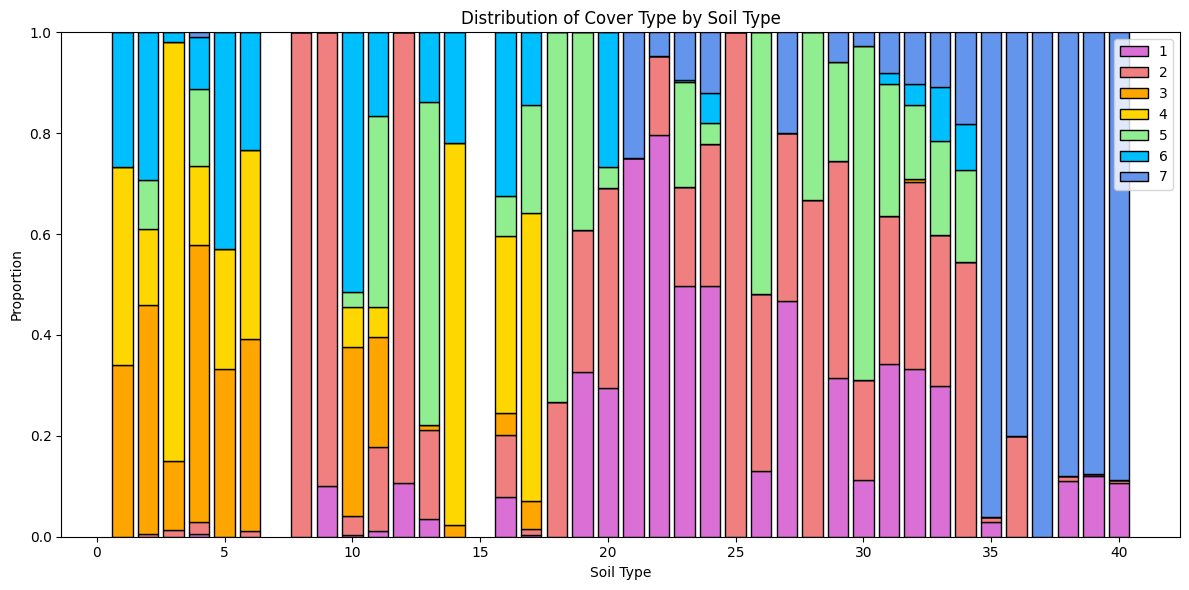

In [ ]:
ct_by_st_props = ct_by_st / ct_by_st.sum()
bb = np.cumsum(ct_by_st_props) - ct_by_st_props

plt.figure(figsize=[12, 6])

for i in range(len(ct_by_st_props)):
  plt.bar(
      ct_by_st_props.columns,
      ct_by_st_props.iloc[i],
      bottom = bb.iloc[i],
      color = palette[i],
      edgecolor= 'k',
      label=str(ct_by_st_props.index[i])
  )

  plt.xlabel("Soil Type")
  plt.ylabel("Proportion")
  plt.title("Distribution of Cover Type by Soil Type")

  plt.legend(loc="upper right")

plt.tight_layout()
plt.show()

## Part 4: Distribution of Elevation by Cover Type

In this section, we will explore the relationship between cover type and elevation. We will start by calculating the average elevation for each of the seven cover types.

Select the `Elevation` and `Cover_Type` columns from `fc`, group the rows by `Cover_Type`, and then calculate the mean `Elevation` for each group. Display the resulting DataFrame.


In [ ]:
ct_by_el = (fc[["Elevation", "Cover_Type"]]
            .groupby('Cover_Type')
            .mean(['Elevation'])
            )
ct_by_el

,Elevation
Cover_Type,
1,3128.025926
2,2922.540278
3,2398.423148
4,2223.420370
5,2786.801389
6,2423.276852
7,3362.769907


We will create histograms to visually explore the distribution of elevations for each of the seven cover types.

Create a figure containing seven subplots arranged in a 2x4 grid (the bottom right subplot will be empty). Each of the subplots should contain a histogram of elevations for regions with one specific cover type. This can be accomplished with the following steps:

1. Set a figure size of `[12, 6]`.
2. Loop over the possible values of `Cover_Type` (which are integers, 1–7). Each time the loop executes:
 a. Create a new subplot.
 b. Add a histogram of `Elevation`, using only the observations corresponding to the current value of `Cover_Type`. Set `bins=np.arange(1800, 4050, 50)` and set the fill color for the bars to be equal to the corresponding color in `palette`. You can add a black border or not, depending on what you think looks better.
 c. Set the title of the subplot to be `"Cover Type X"`, with `"X"` replaced by the appropriate integer.
 d. Set the x-limits to `[1800, 4000]` and set the y-limits to be `[0, 600]`.
 e. Set the axis labels for each subplot to `"Elevation"` and `"Count"`.
3. After the loop finishes, call `plt.tight_layout()`, and then use `plt.show()` to display the figure.


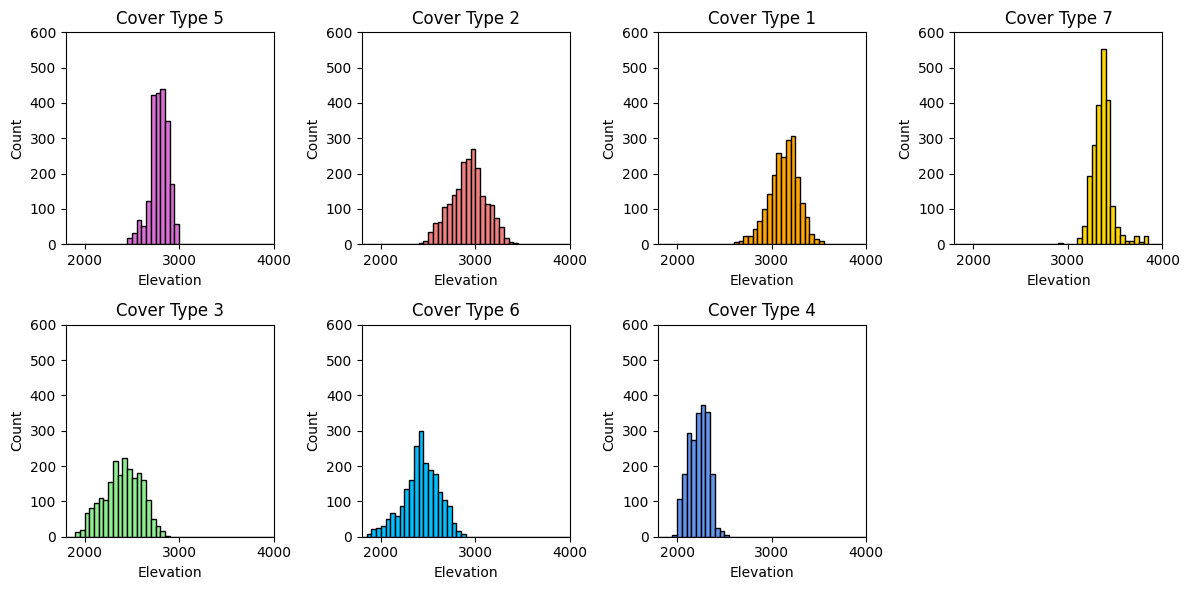

In [ ]:
plt.figure(figsize=[12, 6])

CT_values = fc['Cover_Type'].unique()

for i in range(len(CT_values)):
  level = CT_values[i]
  sel = fc['Cover_Type'] == level

  plt.subplot(2, 4, i + 1)

  plt.hist(fc['Elevation'][sel],
           bins = np.arange(1800, 4050, 50),
           color = palette[i],
           edgecolor='k')

  plt.title(f"Cover Type {level}")
  plt.xlim([1800, 4000])
  plt.ylim([0, 600])
  plt.xlabel("Elevation")
  plt.ylabel("Count")

plt.tight_layout()
plt.show()

## Part 5: Creating Training, Validation, and Test Sets

In this section, we will encode our categorical variables and create training, validation, and test sets. We will start by separating the categorical features, the numerical features, and the labels.

Before moving on, note that we will be using `Cover_Type` as the label variable in our models. All other columns will be used as features. Of the feature columns, `Wilderness_Area` and `Soil_Type` are categorical, while all other feature columns are numerical.

Perform the following steps in a single code cell:

* Create a 2D array named `X_num` by selecting the columns of `fc` that represent numerical features.
* Create a 2D array named `X_cat` by selecting the columns of `fc` that represent categorical features.
* Create a 1D array named `y` by selecting the column of `fc` corresponding to the labels.
* Print the shapes of all three of these arrays with messages as shown below. Add spacing to ensure that the shape tuples are left-aligned.

```
Numerical Feature Array Shape: xxxx
Categorical Feature Array Shape: xxxx
Label Array Shape: xxxx
```

**Note:** The variables created here should be arrays, and not DataFrames or Series. You will need to use `.values`.


In [ ]:
X_num = fc[['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology',
            'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways',
            'Hillshade_9am',	'Hillshade_Noon',	'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points']].values

X_cat = fc[['Wilderness_Area', 'Soil_Type']].values

y = fc['Cover_Type'].values

print(f"Numerical Feature Array Shape: {X_num.shape}")
print(f"Categorical Feature Array Shape: {X_cat.shape}")
print(f"Label Array Shape: {y.shape}")

Numerical Feature Array Shape: (15120, 10)
Categorical Feature Array Shape: (15120, 2)
Label Array Shape: (15120,)


We will now encode the categorical variables using one-hot encoding.

Perform the following steps in a single code cell:

1. Create a `OneHotEncoder()` object setting `sparse_output=False`.
2. Fit the encoder to the categorical features.
3. Use the encoder to encode the categorical features, storing the result in a variable named `X_enc`.
4. Print the shape of `X_enc` with a message as shown below.

```
Encoded Feature Array Shape: xxxx
```


In [ ]:
encoder = OneHotEncoder(sparse_output = False)
encoder.fit(X_cat)
X_enc = encoder.transform(X_cat)

print(f"Encoded Feature Array Shape: {X_enc.shape}")

Encoded Feature Array Shape: (15120, 42)


We will now combine the numerical features with the encoded features.

Perform the following steps in a single code cell:

1. Use `np.hstack` to combine `X_num` and `X_enc` into a single array named `X`.
2. Print the shape of `X` with a message as shown below.

```
Feature Array Shape: xxxx
```


In [ ]:
X = np.hstack((X_num, X_enc))

print(f"Feature Array Shape: {X.shape}")

Feature Array Shape: (15120, 52)


We will now split the data into training, validation, and test sets, using a 70/15/15 split.

Perform the following steps in a single code cell:

* Use `train_test_split()` to split the data into training and holdout sets using a 70/30 split. Name the resulting arrays `X_train`, `X_hold`, `y_train`, and `y_hold`. Set `random_state=1`. Use stratified sampling.
* Use `train_test_split()` to split the holdout data into validation and test sets using a 50/50 split. Name the resulting arrays `X_valid`, `X_test`, `y_valid`, and `y_test`. Set `random_state=1`. Use stratified sampling.
* Print the shapes of `X_train`, `X_valid`, and `X_test` with messages as shown below. Add spacing to ensure that the shape tuples are left-aligned.

```
Training Features Shape: xxxx
Validation Features Shape: xxxx
Test Features Shape: xxxx
```


In [ ]:
X_train, X_hold, y_train, y_hold = train_test_split(
    X,
    y,
    test_size = 0.30,
    random_state = 1,
    stratify = y
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_hold,
    y_hold,
    test_size = 0.50,
    random_state = 1,
    stratify = y_hold
)

print(f"Training Features Shape: {X_train.shape}")
print(f"Validation Features Shape: {X_valid.shape}")
print(f"Test Features Shape: {X_test.shape}")

Training Features Shape: (10584, 52)
Validation Features Shape: (2268, 52)
Test Features Shape: (2268, 52)


## Part 6: Logistic Regression Model

In this section, we will create and evaluate a logistic regression model.

Perform the following steps in a single code cell:

1. Create a logistic regression model named `lr_mod` setting `solver='lbfgs'`, `max_iter=1000`, and `penalty=None`. Your model will likely not converge with the number of iterations we have selected, but for the sake of execution time, we will not worry about increasing it.
2. Fit your model to the training data.
3. Calculate the training and validation accuracy with messages as shown below. Add spacing to ensure that the accuracy scores are left-aligned. Round the scores to 4 decimal places.

```
Training Accuracy: xxxx
Validation Accuracy: xxxx
```


In [ ]:
lr_mod = LogisticRegression(solver='lbfgs', max_iter=1000, penalty=None)

lr_mod.fit(X_train, y_train)

print(f"Training Accuracy: {lr_mod.score(X_train, y_train):.4f}")
print(f"Validation Accuracy: {lr_mod.score(X_valid, y_valid):.4f}")

Training Accuracy: 0.6175
Validation Accuracy: 0.6204


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Part 7: Decision Tree Models

In this section, we will create and evaluate several decision tree models. We will create several decision tree models, each with a different value for the `max_depth` parameter. For each parameter value, we will calculate the training and validation accuracy. We will use the validation scores to select the optimal value for `max_depth`.

Perform the following steps in a single code cell:

1. Create empty lists named `dt_train_acc` and `dt_valid_acc`. These lists will store the accuracy scores that we calculate for each model.
2. Create a range variable named `depth_range` to represent a sequence of integers from 2 to 30.
3. Loop over the values in `depth_range`. Every time the loop executes, perform the following steps.
 a. Use NumPy to set a random seed of 1. This should be done inside the loop.
 b. Create a decision tree model named `temp_tree` with `max_depth` equal to the current value from `depth_range` that is being considered.
 c. Fit the model to the training data.
 d. Calculate the training and validation accuracy for `temp_tree`, appending the resulting values to the appropriate lists.
4. Use `np.argmax` to determine the index of the maximum value in `dt_valid_acc`. Store the result in `dt_idx`.
5. Use `dt_idx` and `depth_range` to find the optimal value for the `max_depth` hyperparameter. Store the result in `dt_opt_depth`.
6. Use `dt_idx` with the lists `dt_train_acc` and `dt_valid_acc` to determine the training and validation accuracies for the optimal model found.
7. Display the values found in Steps 5 and 6 with messages as shown below. Add spacing to ensure that the values replacing the `xxxx` symbols are left-aligned. Round the accuracy scores to 4 decimal places.

```
Optimal value for max_depth: xxxx
Training Accuracy for Optimal Model: xxxx
Validation Accuracy for Optimal Model: xxxx
```


In [ ]:
dt_train_acc = []
dt_valid_acc = []

depth_range = range(2, 30)

for i in depth_range:
  np.random.seed(1)
  temp_tree = DecisionTreeClassifier(max_depth = i, random_state = 1)
  temp_tree.fit(X_train, y_train)

  dt_train_acc.append(temp_tree.score(X_train, y_train))
  dt_valid_acc.append(temp_tree.score(X_valid, y_valid))

dt_idx = np.argmax(dt_valid_acc)
dt_opt_depth = depth_range[dt_idx]

print(f"Optimal value for max_depth: {dt_opt_depth}")
print(f"Training Accuracy for Optimal Model: {dt_train_acc[dt_idx]:.4f}")
print(f"Validation Accuracy for Optimal Model: {dt_valid_acc[dt_idx]:.4f}")

Optimal value for max_depth: 18
Training Accuracy for Optimal Model: 0.9804
Validation Accuracy for Optimal Model: 0.7720


We will now plot the training and validation curves as a function of `max_depth`.

Create a figure with two line plots on the same set of axes. One line plot should plot values of `dt_train_acc` against `depth_range` and the other should plot values of `dt_valid_acc` against `depth_range`. The x-axis should be labeled `"Max Depth"` and the y-axis should be labeled `"Accuracy"`. The plot should contain a legend with two items that read `"Training"` and `"Validation"`.


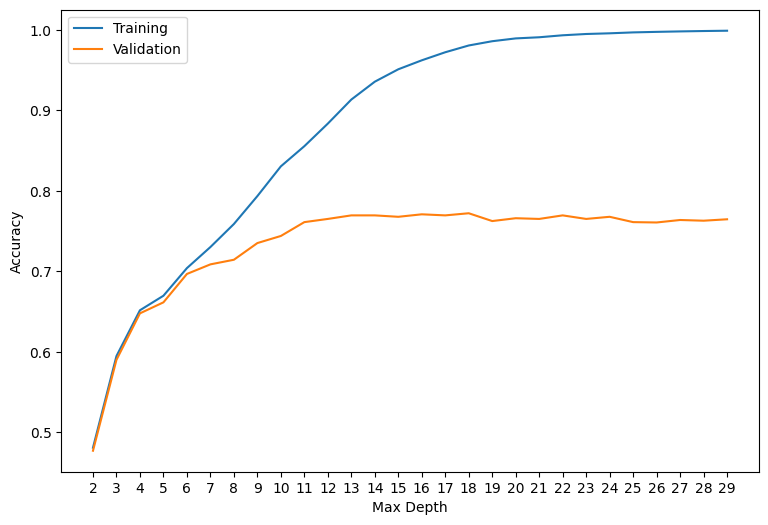

In [ ]:
plt.figure(figsize =([9, 6]))
plt.plot(depth_range, dt_train_acc, label="Training")
plt.plot(depth_range, dt_valid_acc, label="Validation")
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.xticks(depth_range)
plt.legend()
plt.show()

## Part 8: Random Forest Models

In this section, we will create and evaluate several random forest models. We will create several random forest models, each with a different value for the `max_depth` parameter. For each parameter value, we will calculate the training and validation accuracy. We will use the validation scores to select the optimal value for `max_depth`.

Perform the following steps in a single code cell:

1. Create empty lists named `rf_train_acc` and `rf_valid_acc`. These lists will store the accuracy scores that we calculate for each model.
2. Loop over the values in `depth_range` (from Part 7). Every time the loop executes, perform the following steps.
 a. Use NumPy to set a random seed of 1. This should be done inside the loop.
 b. Create a random forest model named `temp_forest` with `max_depth` equal to the current value from `depth_range` that is being considered. Set the parameter `n_estimators` to 100.
 c. Fit the model to the training data.
 d. Calculate the training and validation accuracy for `temp_forest`, appending the resulting values to the appropriate lists.
3. Use `np.argmax` to determine the index of the maximum value in `rf_valid_acc`. Store the result in `rf_idx`.
4. Use `rf_idx` and `depth_range` to find the optimal value for the `max_depth` hyperparameter. Store the result in `rf_opt_depth`.
5. Use `rf_idx` with the lists `rf_train_acc` and `rf_valid_acc` to determine the training and validation accuracies for the optimal model found.
6. Display the values found in Steps 4 and 5 with messages as shown below. Add spacing to ensure that the values replacing the `xxxx` symbols are left-aligned. Round the accuracy scores to 4 decimal places.

```
Optimal value for max_depth: xxxx
Training Accuracy for Optimal Model: xxxx
Validation Accuracy for Optimal Model: xxxx
```


In [ ]:
rf_train_acc = []
rf_valid_acc = []

for i in depth_range:
  temp_forest = RandomForestClassifier(n_estimators=100, max_depth = i, random_state=1)
  temp_forest.fit(X_train, y_train)
  rf_train_acc.append(temp_forest.score(X_train, y_train))
  rf_valid_acc.append(temp_forest.score(X_valid, y_valid))

rf_idx = np.argmax(rf_valid_acc)
rf_idx_opt_depth = depth_range[rf_idx]

print(f"Optimal value for max_depth: {rf_idx_opt_depth} ")
print(f"Training Accuracy for Optimal Model: {rf_train_acc[rf_idx]:.4f}")
print(f"Validation Accuracy for Optimal Model: {rf_valid_acc[rf_idx]:.4f}")


Optimal value for max_depth: 28 
Training Accuracy for Optimal Model: 1.0000
Validation Accuracy for Optimal Model: 0.8677


We will now plot the training and validation curves as a function of `max_depth`.

Create a figure with two line plots on the same set of axes. One line plot should plot values of `rf_train_acc` against `depth_range` and the other should plot values of `rf_valid_acc` against `depth_range`. The x-axis should be labeled `"Max Depth"` and the y-axis should be labeled `"Accuracy"`. The plot should contain a legend with two items that read `"Training"` and `"Validation"`.


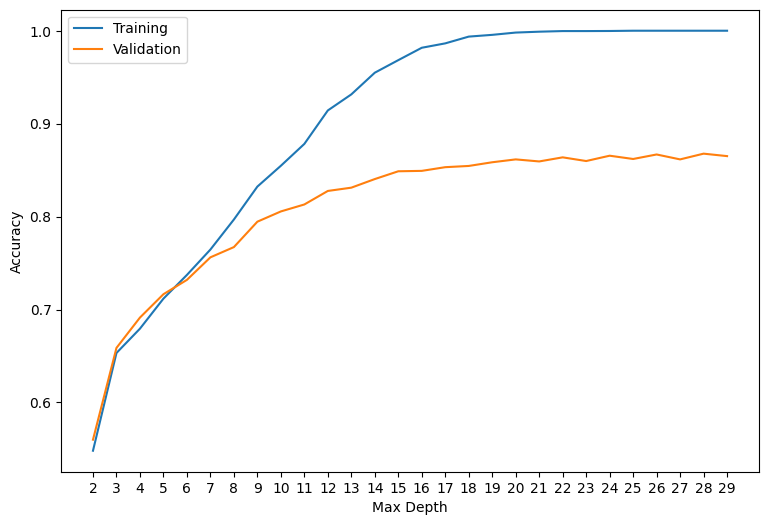

In [ ]:
plt.figure(figsize =([9, 6]))
plt.plot(depth_range, rf_train_acc, label="Training")
plt.plot(depth_range, rf_valid_acc, label="Validation")
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.xticks(depth_range)
plt.legend()
plt.show()

## Part 9: Create and Evaluate Final Model

In this section, we will select our final model and evaluate it on the test set.

Add a brief note below (in this markdown cell or as you complete the code) explaining which of the three types of models (logistic regression, decision tree, or random forest) you will use as your final model, and state what parameter values you will use. Select the model that gave you the best performance on the validation set.

Perform the following steps in a single code cell:

1. If your final model is a decision tree or random forest model, use NumPy to set a random seed of 1.
2. Recreate the best model you found, using the parameter values that produced that model. Store the resulting model in a variable named `final_model`.
3. Fit this model to the training set.
4. Print the training accuracy, validation accuracy, and test accuracy for the final model with messages as shown below. Add spacing to ensure that the accuracy scores are left-aligned, and round the accuracy scores to four decimal places.

```
Training Accuracy for Final Model: xxxx
Validation Accuracy for Final Model: xxxx
Testing Accuracy for Final Model: xxxx
```


In [ ]:
random_state = 1

final_model = RandomForestClassifier(
    n_estimators= 100,
    max_depth = 29,
    random_state = 1
)

final_model.fit(X_train, y_train)

train_acc_final = final_model.score(X_train, y_train)
valid_acc_final = final_model.score(X_valid, y_valid)
test_acc_final = final_model.score(X_test, y_test)

print(f"Training Accuracy for Final Model:   {train_acc_final:.4f}")
print(f"Validation Accuracy for Final Model: {valid_acc_final:.4f}")
print(f"Testing Accuracy for Final Model:    {test_acc_final:.4f}")

Training Accuracy for Final Model:   1.0000
Validation Accuracy for Final Model: 0.8651
Testing Accuracy for Final Model:    0.8620


We will now create and display a confusion matrix detailing the model's performance on the test set.

Use your final model to generate predictions for the test set, storing them in a variable named `test_pred`. Create a confusion matrix by passing `y_test` and `test_pred` to the function `confusion_matrix()` from scikit-learn. This function returns a NumPy array. Store this array in a variable, and then convert it to a DataFrame with row and column names being set equal to the valid labels (i.e. the integers 1–7). Display the resulting DataFrame.


In [ ]:
test_pred = final_model.predict(X_test)

labels = [1, 2, 3, 4, 5, 6, 7]

con_matrix = confusion_matrix(y_test, test_pred)

con_df = pd.DataFrame(
    con_matrix,
    index=labels,
    columns=labels
)

con_df

,1,2,3,4,5,6,7
1,238,60,2,0,5,0,19
2,53,241,6,0,12,9,3
3,0,2,263,19,2,38,0
4,0,0,7,312,0,5,0
5,0,12,4,0,303,5,0
6,0,0,29,10,1,284,0
7,10,0,0,0,0,0,314


We will now generate a classification report to provide further insight into the model's performance on the test set.

Pass the arrays `y_test` and `test_pred` to the function `classification_report()`, printing the result.


In [ ]:
print(classification_report(y_test, test_pred))

              precision    recall  f1-score   support

           1       0.79      0.73      0.76       324
           2       0.77      0.74      0.75       324
           3       0.85      0.81      0.83       324
           4       0.91      0.96      0.94       324
           5       0.94      0.94      0.94       324
           6       0.83      0.88      0.85       324
           7       0.93      0.97      0.95       324

    accuracy                           0.86      2268
   macro avg       0.86      0.86      0.86      2268
weighted avg       0.86      0.86      0.86      2268



# Submission Instructions

1. Perform a Restart and Run All by clicking **Runtime > Restart session and run all**.
2. Copy the link to your notebook by clicking **Share > Copy Link**.
3. Paste the copied link into the notebook renderer tool to generate an HTML export of your notebook.
4. Save the resulting HTML file to your local machine.
5. Submit the HTML file to Canvas.